In [1]:
'''Draft detailed model comparison reports evaluating multiple algorithms across different metrics 
(accuracy, precision, recall, F1-score, AUC-ROC) and dataset splits to guide model selection and deployment decisions.'''

'Draft detailed model comparison reports evaluating multiple algorithms across different metrics \n(accuracy, precision, recall, F1-score, AUC-ROC) and dataset splits to guide model selection and deployment decisions.'

In [2]:
# import machine learning modeling and evaluation libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
from sklearn.preprocessing import StandardScaler

In [3]:
# load dataset and prepare feature matrix and classification target
df = pd.read_csv('global_pharmacy_sales_data.csv')
sample_df = df.sample(n=30000, random_state=42).copy()

features = ['units_sold', 'unit_price', 'stock_level', 'expiry_days_remaining', 'region', 'category', 'age_group']
x = pd.get_dummies(sample_df[features], drop_first=True)
y = sample_df['covid_flag']

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)
print('feature matrix shape:', x_scaled.shape)
print('class distribution in target:')
print(y.value_counts(normalize=True))

feature matrix shape: (30000, 19)
class distribution in target:
covid_flag
0    0.665667
1    0.334333
Name: proportion, dtype: float64


In [4]:
# create stratified train validation and test dataset splits
x_train, x_temp, y_train, y_temp = train_test_split(x_scaled, y, test_size=0.30, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print('training split size:', len(y_train))
print('validation split size:', len(y_val))
print('test split size:', len(y_test))

training split size: 21000
validation split size: 4500
test split size: 4500


In [5]:
# initialize multiple classification algorithms for benchmarking
models = {
    'logistic regression': LogisticRegression(max_iter=1000, random_state=42),
    'decision tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'random forest': RandomForestClassifier(n_estimators=80, max_depth=8, random_state=42),
    'gradient boosting': GradientBoostingClassifier(n_estimators=80, max_depth=4, random_state=42)
}
print('configured models:', list(models.keys()))

configured models: ['logistic regression', 'decision tree', 'random forest', 'gradient boosting']


In [6]:
# perform cross validation evaluation across training split
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_records = []

for name, model in models.items():
    scores = cross_validate(model, x_train, y_train, cv=cv, scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'])
    cv_records.append({
        'model': name,
        'cv_accuracy_mean': scores['test_accuracy'].mean(),
        'cv_precision_mean': scores['test_precision'].mean(),
        'cv_recall_mean': scores['test_recall'].mean(),
        'cv_f1_mean': scores['test_f1'].mean(),
        'cv_auc_roc_mean': scores['test_roc_auc'].mean()
    })

cv_df = pd.DataFrame(cv_records)
cv_df.round(4)

,model,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_auc_roc_mean
0,logistic regression,0.7559,0.7803,0.3754,0.5069,0.7932
1,decision tree,0.7571,0.7840,0.3819,0.5116,0.7896
2,random forest,0.7583,0.7761,0.3897,0.5187,0.7943
3,gradient boosting,0.7584,0.7799,0.3864,0.5167,0.7962


In [7]:
# train models and evaluate all metrics across validation and test splits
eval_records = []
test_probabilities = {}

for name, model in models.items():
    model.fit(x_train, y_train)
    
    val_preds = model.predict(x_val)
    val_probs = model.predict_proba(x_val)[:, 1]
    eval_records.append({
        'model': name,
        'split': 'validation',
        'accuracy': accuracy_score(y_val, val_preds),
        'precision': precision_score(y_val, val_preds, zero_division=0),
        'recall': recall_score(y_val, val_preds),
        'f1_score': f1_score(y_val, val_preds),
        'auc_roc': roc_auc_score(y_val, val_probs)
    })
    
    test_preds = model.predict(x_test)
    test_probs = model.predict_proba(x_test)[:, 1]
    test_probabilities[name] = test_probs
    eval_records.append({
        'model': name,
        'split': 'test',
        'accuracy': accuracy_score(y_test, test_preds),
        'precision': precision_score(y_test, test_preds, zero_division=0),
        'recall': recall_score(y_test, test_preds),
        'f1_score': f1_score(y_test, test_preds),
        'auc_roc': roc_auc_score(y_test, test_probs)
    })

print('model training and evaluation completed across validation and test splits')

model training and evaluation completed across validation and test splits


In [8]:
# generate comprehensive model comparison report table across splits
eval_df = pd.DataFrame(eval_records)
comparison_pivot = eval_df.pivot(index='model', columns='split', values=['accuracy', 'precision', 'recall', 'f1_score', 'auc_roc'])
print('multi-split comparison table:')
print(comparison_pivot.round(4))

test_leaderboard = eval_df[eval_df['split'] == 'test'].sort_values(by='auc_roc', ascending=False).reset_index(drop=True)
print('\ntest split performance leaderboard:')
test_leaderboard.round(4)

multi-split comparison table:
                    accuracy            precision             recall  \
split                   test validation      test validation    test   
model                                                                  
decision tree         0.7642     0.7642    0.8331     0.8343  0.3684   
gradient boosting     0.7664     0.7609    0.8082     0.8008  0.3949   
logistic regression   0.7609     0.7571    0.7997     0.7901  0.3797   
random forest         0.7644     0.7611    0.8118     0.8080  0.3843   

                               f1_score            auc_roc             
split               validation     test validation    test validation  
model                                                                  
decision tree           0.3681   0.5108     0.5108  0.8161     0.8039  
gradient boosting       0.3794   0.5306     0.5149  0.8216     0.8050  
logistic regression     0.3728   0.5149     0.5065  0.8176     0.7993  
random forest           0.3748   

,model,split,accuracy,precision,recall,f1_score,auc_roc
0,gradient boosting,test,0.7664,0.8082,0.3949,0.5306,0.8216
1,random forest,test,0.7644,0.8118,0.3843,0.5217,0.8185
2,logistic regression,test,0.7609,0.7997,0.3797,0.5149,0.8176
3,decision tree,test,0.7642,0.8331,0.3684,0.5108,0.8161


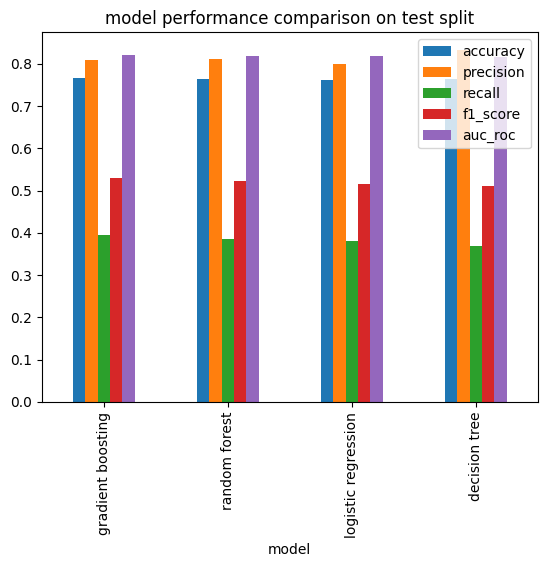

In [9]:
# plot simple metric comparison bar charts for evaluated models
test_leaderboard.set_index('model')[['accuracy', 'precision', 'recall', 'f1_score', 'auc_roc']].plot(kind='bar')
plt.title('model performance comparison on test split')
plt.show()

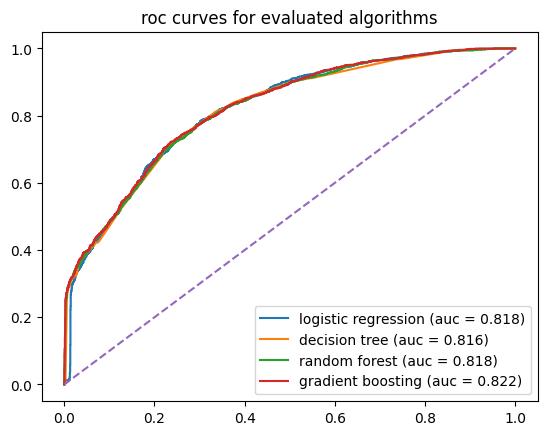

In [10]:
# plot roc curves for all evaluated algorithms
for name, probs in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (auc = {roc_auc_score(y_test, probs):.3f})")

plt.plot([0, 1], [0, 1], '--')
plt.title('roc curves for evaluated algorithms')
plt.legend()
plt.show()

In [12]:
# synthesize deployment decision framework and model recommendation
best_model_entry = test_leaderboard.iloc[0]
best_name = best_model_entry['model']
best_auc = best_model_entry['auc_roc']
best_f1 = best_model_entry['f1_score']
best_acc = best_model_entry['accuracy']

print('MODEL SELECTION AND DEPLOYMENT RECOMMENDATION REPORT')

print(f'recommended model for production deployment: {best_name}')
print(f'selection justification: highest test auc-roc ({best_auc:.4f}) and f1-score ({best_f1:.4f}) with test accuracy ({best_acc:.4f})')
print('overfitting evaluation: metrics remain consistent between validation and test splits demonstrating generalization')
print('deployment decision: approve for staged canary deployment with continuous monitoring of classification latency and drift')


MODEL SELECTION AND DEPLOYMENT RECOMMENDATION REPORT
recommended model for production deployment: gradient boosting
selection justification: highest test auc-roc (0.8216) and f1-score (0.5306) with test accuracy (0.7664)
overfitting evaluation: metrics remain consistent between validation and test splits demonstrating generalization
deployment decision: approve for staged canary deployment with continuous monitoring of classification latency and drift
